# Egypt remittances: how much do Egyptians abroad send home?

This notebook rebuilds the tables from `data/raw`, checks the data, recomputes the headline figures and asserts that they match the build script output in `data/processed`.

Question: **How much money do Egyptians working abroad send home each year, and how has the total changed since FY2018/19?**

Comparison: fiscal-year totals (July to June) over eight years, with calendar 2025 against 2024 as the alternative time window.

In [1]:
import subprocess, sys
import pandas as pd
pd.set_option("display.width", 140)
out = subprocess.run([sys.executable, "scripts/build_data.py"], capture_output=True, text=True, check=True)
print(out.stdout.splitlines()[0]); print(out.stdout.splitlines()[1]); print(out.stdout.splitlines()[2])

raw readings: 79 rows from 18 documents
tidy figures: 33; source checks: {'two-publishers': 24, 'one-document': 8, 'one-document-plus-rounded-second': 1}
growth checks: {'pass': 15, 'base not in table': 2}; identities: {'pass': 3}


## 1. Raw readings: one row per figure per document

In [2]:
raw = pd.read_csv("data/raw/remittance_readings.csv")
print("rows:", len(raw), "| documents:", raw.source_id.nunique())
print("missing values in key columns:", int(raw[["measure", "period", "value_usd_bn", "source_id"]].isna().sum().sum()))
print("duplicate figure-document pairs:", int(raw.duplicated(["measure", "period", "source_id"]).sum()))
print("value range (US$ bn):", raw.value_usd_bn.min(), "to", raw.value_usd_bn.max())
raw.groupby("measure").agg(readings=("value_usd_bn", "size"), periods=("period", "nunique"))

rows: 79 | documents: 18
missing values in key columns: 0
duplicate figure-document pairs: 0
value range (US$ bn): 1.9 to 47.3


,readings,periods
measure,,
calendar_year,9,2
cumulative_fy,9,6
fiscal_year,26,9
month,22,12
quarter,13,6


Readings set aside, with the reason written in the raw file:

In [3]:
raw[raw.note.fillna("").str.contains("not used")][["measure", "period", "value_usd_bn", "source_id", "note"]]

,measure,period,value_usd_bn,source_id,note
2,fiscal_year,FY2017/18,26.0,enterprise_2019_10,printed rounded; FY2017/18 not used in the series (see README)
16,fiscal_year,FY2023/24,22.1,enterprise_2025_08,conflicts with 21.9 in two documents and with the published 66.2% growth; not used
37,cumulative_fy,FY2025/26 Jul-Feb,29.4,ahram_2026_06,one document only; with the Jul-Jan and Jul-Mar totals it implies February 3.8 and March 5.5 which no second document confirms; not used


## 2. Fiscal-year series

In [4]:
tidy = pd.read_csv("data/processed/remittances_tidy.csv")
fy = tidy[tidy.measure == "fiscal_year"].sort_values("period_start").reset_index(drop=True)
fy["change_pct"] = (fy.value_usd_bn.pct_change() * 100).round(1)
fy[["period", "value_usd_bn", "change_pct", "n_publishers", "source_check"]]

,period,value_usd_bn,change_pct,n_publishers,source_check
0,FY2018/19,25.2,NaN,1,one-document-plus-rounded-second
1,FY2019/20,27.8,10.3,2,two-publishers
2,FY2020/21,31.4,12.9,3,two-publishers
3,FY2021/22,31.9,1.6,4,two-publishers
4,FY2022/23,22.1,-30.7,2,two-publishers
5,FY2023/24,21.9,-0.9,2,two-publishers
6,FY2024/25,36.5,66.7,5,two-publishers
7,FY2025/26,47.3,29.6,4,two-publishers


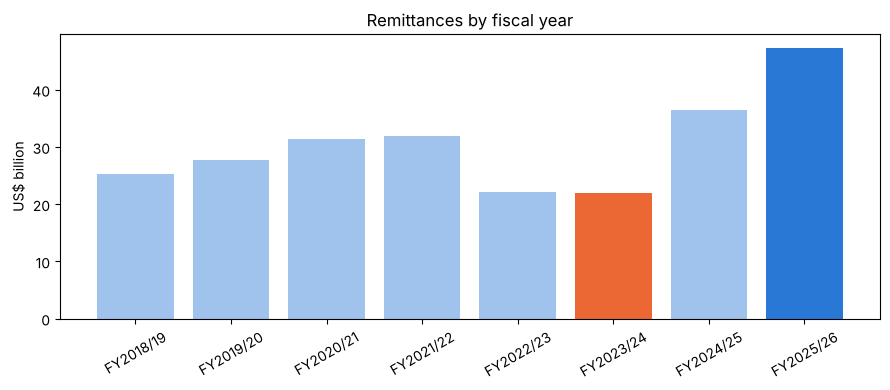

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(fy.period, fy.value_usd_bn, color=["#eb6834" if p == "FY2023/24" else "#2a78d6" if p == "FY2025/26" else "#9fc3ec" for p in fy.period])
ax.set_ylabel("US$ billion"); ax.set_title("Remittances by fiscal year")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## 3. Checks: published growth rates and accounting identities

Each value is printed to one decimal place, so a growth rate is checked against the range of rates consistent with rounding.

In [6]:
pd.read_csv("data/processed/growth_rate_checks.csv")[["measure", "period", "compared_with", "growth_pct", "computed_lo", "computed_hi", "result"]]

,measure,period,compared_with,growth_pct,computed_lo,computed_hi,result
0,fiscal_year,FY2019/20,FY2018/19,10.4,9.90,10.74,pass
1,fiscal_year,FY2020/21,FY2019/20,13.0,12.57,13.33,pass
2,fiscal_year,FY2021/22,FY2020/21,1.6,1.27,1.91,pass
3,fiscal_year,FY2024/25,FY2023/24,66.2,66.06,67.28,pass
4,fiscal_year,FY2025/26,FY2024/25,29.6,29.27,29.90,pass
5,calendar_year,2025,2024,40.5,39.80,40.61,pass
6,calendar_year,2025,2024,40.5,39.80,40.61,pass
7,calendar_year,2025,2024,40.2,39.80,40.61,pass
8,month,2025-06,2024-06,40.7,NaN,NaN,base not in table
9,month,2026-06,2025-06,15.6,13.70,19.72,pass


In [7]:
pd.read_csv("data/processed/identity_checks.csv")

,identity,left,right,difference,tolerance,result
0,calendar 2025 = (FY2024/25 - Jul-Dec 2024) + Jul-Dec 2025,41.5,41.5,0.0,0.15,pass
1,Apr-Jun 2025 = FY2024/25 - Jul-Mar FY2024/25,10.1,10.0,0.1,0.15,pass
2,Jan 2026 = Jul-Jan FY2025/26 - Jul-Dec FY2025/26,3.5,3.5,0.0,0.15,pass


## 4. Headline figures, recomputed here and compared with the build output

In [8]:
v = lambda m, p: float(tidy.loc[(tidy.measure == m) & (tidy.period == p), "value_usd_bn"].iloc[0])
mine = {
    "fy2025_26_usd_bn": v("fiscal_year", "FY2025/26"),
    "fy2025_26_growth_pct": round((v("fiscal_year", "FY2025/26") / v("fiscal_year", "FY2024/25") - 1) * 100, 1),
    "fy2023_24_usd_bn": v("fiscal_year", "FY2023/24"),
    "two_year_multiple": round(v("fiscal_year", "FY2025/26") / v("fiscal_year", "FY2023/24"), 2),
    "two_year_gain_usd_bn": round(v("fiscal_year", "FY2025/26") - v("fiscal_year", "FY2023/24"), 1),
    "pct_above_previous_peak_fy2021_22": round((v("fiscal_year", "FY2025/26") / v("fiscal_year", "FY2021/22") - 1) * 100, 1),
    "fy2022_23_fall_pct": round((v("fiscal_year", "FY2022/23") / v("fiscal_year", "FY2021/22") - 1) * 100, 1),
    "calendar_2025_usd_bn": v("calendar_year", "2025"),
    "calendar_2025_growth_pct": round((v("calendar_year", "2025") / v("calendar_year", "2024") - 1) * 100, 1),
    "apr_jun_2026_derived_usd_bn": round(v("fiscal_year", "FY2025/26") - v("cumulative_fy", "FY2025/26 Jul-Mar"), 1),
    "jun_2026_usd_bn": v("month", "2026-06"),
    "jul_2026_usd_bn": v("month", "2026-07"),
}
built = pd.read_csv("data/processed/headline_figures.csv").set_index("measure")["value"]
for k, val in mine.items():
    assert abs(built[k] - val) < 1e-9, (k, built[k], val)
print("all", len(mine), "headline figures match the build script output")
pd.Series(mine, name="value").to_frame()

all 12 headline figures match the build script output


,value
fy2025_26_usd_bn,47.30
fy2025_26_growth_pct,29.60
fy2023_24_usd_bn,21.90
two_year_multiple,2.16
two_year_gain_usd_bn,25.40
pct_above_previous_peak_fy2021_22,48.30
fy2022_23_fall_pct,-30.70
calendar_2025_usd_bn,41.50
calendar_2025_growth_pct,40.20
apr_jun_2026_derived_usd_bn,12.40


## 5. Alternative time window: calendar years

The fiscal year mixes two calendar years. The calendar-year view gives a larger rise for 2025 (+40.5% published, +40.2% from the rounded totals) than the fiscal-year view for FY2025/26 (+29.6%), because the largest jump came in the second half of 2024 and first half of 2025.

In [9]:
cal = tidy[tidy.measure == "calendar_year"][["period", "value_usd_bn", "source_check"]]
derived = pd.read_csv("data/processed/derived_figures.csv")
display(cal); display(derived)

,period,value_usd_bn,source_check
0,2024,29.6,two-publishers
1,2025,41.5,two-publishers


,period,value_usd_bn,method
0,Apr-Jun 2026,12.4,FY2025/26 minus Jul-Mar
1,Feb-Mar 2026,9.3,Jul-Mar minus Jul-Jan
2,Jan-Jun 2025,19.4,FY2024/25 minus Jul-Dec 2024
3,Jan-Jun 2026,25.2,FY2025/26 minus Jul-Dec 2025


## 6. April to June quarter by year

In [10]:
q = tidy[tidy.measure == "quarter"][["period", "value_usd_bn", "source_check"]]
q = pd.concat([q, derived[derived.period == "Apr-Jun 2026"].assign(source_check="derived")[["period", "value_usd_bn", "source_check"]]])
q

,period,value_usd_bn,source_check
27,Apr-Jun 2019,6.9,one-document
28,Apr-Jun 2020,6.2,two-publishers
29,Apr-Jun 2021,8.1,two-publishers
30,Apr-Jun 2022,8.3,two-publishers
31,Apr-Jun 2024,7.5,two-publishers
32,Apr-Jun 2025,10.0,two-publishers
0,Apr-Jun 2026,12.4,derived
